### Baselines

Sets up the train/test split and cross-validation, and evaluates two baseline models on the training participants.

**Input:** `data/processed/harth_windows.csv` (created by `02_preprocessing.ipynb`)
**Output:** cross-validated results for a dummy baseline and logistic regression.

**How to run:** run `02_preprocessing.ipynb` first. Then activate the environment and run all cells from top to bottom.

**Sections**
1. Train/test split by participant (18 training, 4 test)
2. 5-fold StratifiedGroupKFold cross-validation
4. Baselines: dummy (most frequent class) and logistic regression
5. Results table (macro F1 and balanced accuracy, mean ± SD across folds), confusion matrices and interpretation


#### Some Leakage Risks Considered

| Risk | Why it leaks | How to prevent it |
|---|---|---|
| The same participant in training and test data | The model could recognise the person rather than the activity since windows from the same person are very simlar, so scores would look better than they woud on new people | Participants are split into training and test sets, and cross-validation using StratifiedGroupKFold, so each person is in only one fold |
| Timestamp or index used as a feature | The model could learn when the window happened instead of the activity & use it as a shortcut | Timestamp only used for gap detection and creating windows, and index columns were dropped during cleaning, both not used as features |
| Fit scaling on all data | The scaler learns means and SDs, so if it is fitted on all the data, the validation or test participant values shape how the training data is transformed | the scaler goes inside a scikit-learn Pipeline, so in cross-validation it's refitted on each fold's training participants only, and before the test, it's fitted on all the training participants only |


In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
from pathlib import Path
print(Path.cwd())
# Create data directory 
data_directory = Path("../data/processed")
print(list(data_directory.iterdir()))

C:\Users\sarab\Projects\CT4101 ML Project\Machine_Learning_Portfolio_Project\notebooks
[WindowsPath('../data/processed/harth_windows.csv')]


In [3]:
# Read harth_windows csv file
harth_windows = pd.read_csv(data_directory/"harth_windows.csv")
harth_windows.head()

,back_x_mean,back_y_mean,back_z_mean,thigh_x_mean,thigh_y_mean,thigh_z_mean,back_mag_mean,thigh_mag_mean,back_x_sd,back_y_sd,...,back_x_range,back_y_range,back_z_range,thigh_x_range,thigh_y_range,thigh_z_range,back_mag_range,thigh_mag_range,activity,subject
0,-0.985535,0.076321,0.071897,-0.951721,0.066909,-0.300923,0.991294,1.000641,0.008179,0.015925,...,0.042021,0.106730,0.049085,0.026857,0.087156,0.065944,0.049257,0.030911,walking,S006
1,-0.990118,0.098939,0.052922,-0.970774,0.017955,-0.240916,0.996594,1.000600,0.006710,0.014250,...,0.021219,0.064559,0.039445,0.023676,0.082334,0.048104,0.021273,0.019548,standing,S006
2,-0.985489,0.114645,0.066351,-0.971958,0.013050,-0.227268,0.994405,0.998316,0.003794,0.007793,...,0.019534,0.039422,0.033895,0.007465,0.040694,0.031032,0.019653,0.008874,standing,S006
3,-0.986061,0.112886,0.061172,-0.971738,0.010761,-0.241171,0.994513,1.001399,0.004785,0.013871,...,0.021073,0.048442,0.034815,0.035844,0.036097,0.062481,0.023155,0.031511,standing,S006
4,-0.982235,0.143961,0.078188,-0.981988,0.051999,-0.167089,0.996508,1.000266,0.007308,0.028004,...,0.034060,0.127701,0.091557,0.051724,0.117495,0.212539,0.030263,0.033056,standing,S006


In [4]:
pd.crosstab(harth_windows["subject"], harth_windows["activity"])

activity,cycling,lying,running,shuffling,sitting,stairs,standing,walking
subject,,,,,,,,
S006,276,129,0,25,2520,25,514,153
S008,164,0,0,398,5853,27,1136,353
S009,2609,0,0,0,0,18,108,102
S010,0,0,0,384,928,164,1651,3390
S012,0,377,42,89,6229,120,404,212
S013,53,147,68,532,4464,104,938,591
S014,111,184,46,180,4727,152,937,461
S015,180,1261,56,116,3896,220,1241,987
S016,214,795,53,205,3793,46,952,728


#### Choosing train/test split

The data is split by participant, so no person appears in both the training and test sets. I split the data into approx. 80% training data (18 participants) and 20% test data (4 participants)

- **Training (18 participants):** S006, S008, S009, S010, S012, S013, S014, S015, S016, S017, S020, S021, S023, S024, S026, S027, S028, S029
- **Test (4 participants):** S018, S019, S022, S025
- The test set contains 220308 windows (19% of all windows).

**How the test participants were chosen:** manually, based on a crosstab of windows per activity for each participant, before any modelling. 
##### The aims were:
- every one of the 8 activities appears in both the training and test sets
- the main contributors to the rarest activities stay in training, so the model has enough examples to learn from: S027 (about half of all running), and S009 and S026 (most of the cycling)
- the test set includes participants from both recording groups (S025 from the S023 to S029 group, which has more walking and running)

**Limitation:** much of the test set's cycling comes from one participant (S025), so the test result for cycling mostly reflects one person.

In [5]:
# Create a DataFrame with training data
TRAINING = ["S006", "S008", "S009", "S010", "S012", "S013", "S014", "S015", "S016", "S017", "S020", "S021", "S023", "S024", "S026", "S027", "S028", "S029"]

harth_windows_training = harth_windows[harth_windows["subject"].isin(TRAINING)]
harth_windows_training.shape
harth_windows_training.head()

,back_x_mean,back_y_mean,back_z_mean,thigh_x_mean,thigh_y_mean,thigh_z_mean,back_mag_mean,thigh_mag_mean,back_x_sd,back_y_sd,...,back_x_range,back_y_range,back_z_range,thigh_x_range,thigh_y_range,thigh_z_range,back_mag_range,thigh_mag_range,activity,subject
0,-0.985535,0.076321,0.071897,-0.951721,0.066909,-0.300923,0.991294,1.000641,0.008179,0.015925,...,0.042021,0.106730,0.049085,0.026857,0.087156,0.065944,0.049257,0.030911,walking,S006
1,-0.990118,0.098939,0.052922,-0.970774,0.017955,-0.240916,0.996594,1.000600,0.006710,0.014250,...,0.021219,0.064559,0.039445,0.023676,0.082334,0.048104,0.021273,0.019548,standing,S006
2,-0.985489,0.114645,0.066351,-0.971958,0.013050,-0.227268,0.994405,0.998316,0.003794,0.007793,...,0.019534,0.039422,0.033895,0.007465,0.040694,0.031032,0.019653,0.008874,standing,S006
3,-0.986061,0.112886,0.061172,-0.971738,0.010761,-0.241171,0.994513,1.001399,0.004785,0.013871,...,0.021073,0.048442,0.034815,0.035844,0.036097,0.062481,0.023155,0.031511,standing,S006
4,-0.982235,0.143961,0.078188,-0.981988,0.051999,-0.167089,0.996508,1.000266,0.007308,0.028004,...,0.034060,0.127701,0.091557,0.051724,0.117495,0.212539,0.030263,0.033056,standing,S006


In [6]:
# Create a DataFrame with test data
TEST = ["S018", "S019", "S022", "S025"]

harth_windows_test = harth_windows[harth_windows["subject"].isin(TEST)]
harth_windows_test.shape

(22308, 26)

In [7]:
# Separate the inputs, target and groups
X = harth_windows_training.drop(columns=["activity", "subject"]) # inputs (24 features)
y = harth_windows_training["activity"] # target (activity column)
groups = harth_windows_training["subject"] # groups (who each row belongs to)

In [8]:
# 5 fold cross-validation with Stratified Group KFold
# Each participant stays in one fold and each fold gets a simialr mix of activities 
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

In [9]:
# Check each fold
for train_index, validation_index in cv.split(X, y, groups):
    print(groups.iloc[validation_index].unique())
    print(y.iloc[validation_index].value_counts())

<StringArray>
['S012', 'S015', 'S029']
Length: 3, dtype: str
activity
sitting      10193
walking       3608
standing      1856
lying         1734
running        451
cycling        385
stairs         363
shuffling      285
Name: count, dtype: int64
<StringArray>
['S008', 'S017', 'S028']
Length: 3, dtype: str
activity
sitting      10259
walking       3964
standing      1845
lying          910
shuffling      526
stairs         317
cycling        317
running         99
Name: count, dtype: int64
<StringArray>
['S014', 'S016', 'S023', 'S026']
Length: 4, dtype: str
activity
sitting      8869
walking      3029
cycling      2670
standing     2072
lying        1309
running       772
stairs        579
shuffling     435
Name: count, dtype: int64
<StringArray>
['S006', 'S010', 'S020', 'S027']
Length: 4, dtype: str
activity
sitting      8379
walking      4220
running      2689
standing     2511
lying        1287
cycling       577
shuffling     502
stairs        277
Name: count, dtype: int64
<StringA

#### Notes on CV results
All 18 training participants appear in exactly one validation fold, and every fold contains all 8 activities. Running is unevenly spread because S027 contributes over half of it.

#### Baseline Models

In [10]:
# Create Dummy baseline to always predict the most common class (sitting)
# Shows the score achievable without learning anything
model_dummy = DummyClassifier(strategy="most_frequent")

In [11]:
# Evaluate the dummy model with grouped 5-fold cross-validation
results_dummy = cross_validate(model_dummy, X, y, groups=groups, cv=cv, scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"})

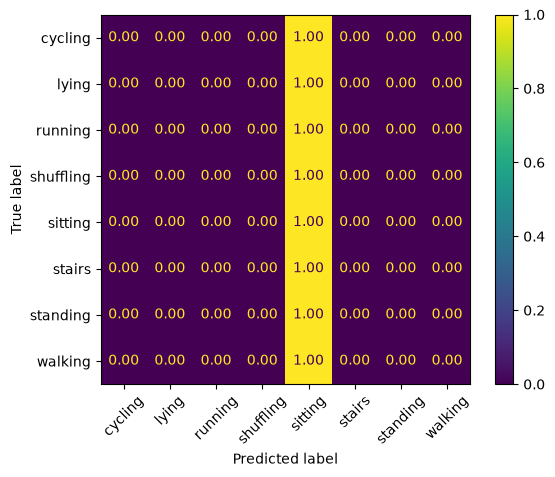

In [12]:
# Cross-validated predictions, each window is predicted by the model trained without its fold
predictions_dummy = cross_val_predict(model_dummy, X, y, groups=groups, cv=cv)
# Plot Confusion matrix
ConfusionMatrixDisplay.from_predictions(y, predictions_dummy, normalize="true", values_format=".2f", xticks_rotation=45)

In [13]:
# Create Logistic regression baseline
model_logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

In [14]:
# Evaluate the dummy model with grouped 5-fold cross-validation
results_logreg = cross_validate(model_logreg, X, y, groups=groups, cv=cv, scoring={"f1": "f1_macro", "balanced_accuracy": "balanced_accuracy"})

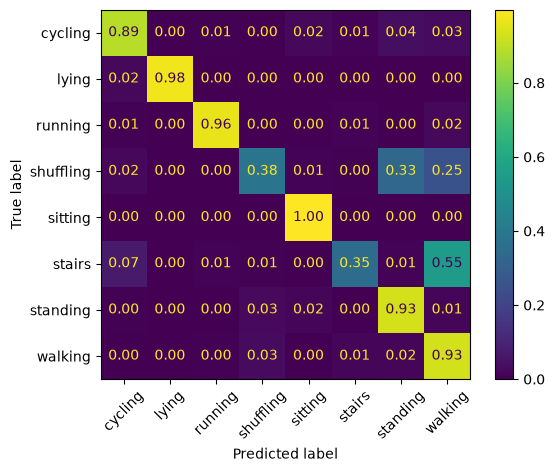

In [15]:
# Cross-validated predictions, each window is predicted by the model trained without its fold
predictions_logreg = cross_val_predict(model_logreg, X, y, groups=groups, cv=cv)
# Plot Confusion matrix
ConfusionMatrixDisplay.from_predictions(y, predictions_logreg, normalize="true", values_format=".2f", xticks_rotation=45)

In [16]:
# Dummy Baseline Results: Mean and standard deviation of each metric across the 5 folds
mean_f1_dummy = results_dummy["test_f1"].mean().round(3)
sd_f1_dummy = results_dummy["test_f1"].std().round(3)
mean_balancedaccuracy_dummy = results_dummy["test_balanced_accuracy"].mean().round(3)
sd_balancedaccuracy_dummy = results_dummy["test_balanced_accuracy"].std().round(3)

results_dummy_dict = { "Model": "Dummy (most frequent)",
                       "Macro F1": f"{mean_f1_dummy:.3f} ± {sd_f1_dummy:.3f}",
                       "Balanced Accuracy": f"{mean_balancedaccuracy_dummy:.3f} ± {sd_balancedaccuracy_dummy:.3f}"}
results_dummy_dict                     

{'Model': 'Dummy (most frequent)',
 'Macro F1': '0.081 ± 0.007',
 'Balanced Accuracy': '0.125 ± 0.000'}

In [17]:
# Logistic Regression Baseline Results: Mean and standard deviation of each metric across the 5 folds
mean_f1_logreg = results_logreg["test_f1"].mean().round(3)
sd_f1_logreg = results_logreg["test_f1"].std().round(3)
mean_balancedaccuracy_logreg = results_logreg["test_balanced_accuracy"].mean().round(3)
sd_balancedaccuracy_logreg = results_logreg["test_balanced_accuracy"].std().round(3)

results_logreg_dict = { "Model": "Logistic Regression",
                       "Macro F1": f"{mean_f1_logreg:.3f} ± {sd_f1_logreg:.3f}",
                       "Balanced Accuracy": f"{mean_balancedaccuracy_logreg:.3f} ± {sd_balancedaccuracy_logreg:.3f}"}
results_logreg_dict 

{'Model': 'Logistic Regression',
 'Macro F1': '0.809 ± 0.039',
 'Balanced Accuracy': '0.802 ± 0.036'}

In [18]:
# Combine both models into one results table (mean ± SD across folds)
results_table = [results_dummy_dict, results_logreg_dict]
results_table = pd.DataFrame(results_table).set_index("Model")
results_table

,Macro F1,Balanced Accuracy
Model,,
Dummy (most frequent),0.081 ± 0.007,0.125 ± 0.000
Logistic Regression,0.809 ± 0.039,0.802 ± 0.036


#### Interpretation of the results

- The dummy baseline scores 0.081 macro F1 and 0.125 balanced accuracy
- The logistic regression baseline scores 0.809 ± 0.039 macro F1, which is a good performance and far above the dummy baseline.
- The model performes well for distinctive movements and ones with more recorded minutes (walking, standing, sitting, running, lying and cycling), but  performes poorly for less distinctive activities with fewer recorded minutes (stairs and shuffling), which it mostly confuses with walking and walking or standing, respectively.
